
# OpenMP

In [44]:
import numpy as np 
import os
import pandas as pd
import matplotlib as plt

os.environ["MPLCONFIGDIR"] = "/tmp"

# Detect project root directory whether running from docs/ or project root
current_dir = os.path.abspath(os.getcwd())
if os.path.basename(current_dir) == "docs":
    PROJECT_ROOT = os.path.dirname(current_dir)
else:
    PROJECT_ROOT = current_dir

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
print(f"Project root: {PROJECT_ROOT}")
print(f"Results dir:  {RESULTS_DIR}")

def load_results(csv_name):
    path = os.path.join(RESULTS_DIR, csv_name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Resultatenbestand niet gevonden: {path}")
    return pd.read_csv(path)


Project root: /home/matha/Projects/c/uni/pds/kmeans
Results dir:  /home/matha/Projects/c/uni/pds/kmeans/results


We hadden nog 2 versies van omp waaruit we moesten kiezen
Na vergelijken van die twee versies, omp2 is duidelijk een stuk sneller lol, en zullen we verder gebruiken

In [45]:
ompcomp = load_results("omp_comparison.csv")
summary = (
    ompcomp.groupby(["label"])["seconds"]
    .agg(seconds="mean", std="std", n_runs="count")
    .reset_index()
)
print(summary)


    label   seconds       std  n_runs
0    omp1  0.333581  0.005093      15
1    omp2  0.089265  0.002692      15
2  serial  1.817339  0.050534      15


 k  seconds_mean  seconds_std  steps_mean_mean  steps_mean_std  steps_total_mean  steps_total_std  perstep_mean  perstep_std    bestdist  n_runs
 1      0.420876     0.008841              2.0             0.0              10.0              0.0      0.042088     0.000884 173643000.0       3
 2      0.944574     0.025403              4.0             0.0              20.0              0.0      0.047229     0.001270  83464600.0       3
 3     95.279467     2.822850            423.2             0.0            2116.0              0.0      0.045028     0.001334  41840200.0       3
 4      1.411237     0.015867              4.4             0.0              22.0              0.0      0.064147     0.000721  10674700.0       3
 5      1.591837     0.014384              4.2             0.0              21.0              0.0      0.075802     0.000685   1607340.0       3
 6    398.317000     1.723252           1090.8             0.0            5454.0              0.0      0.073032     0.000316   153

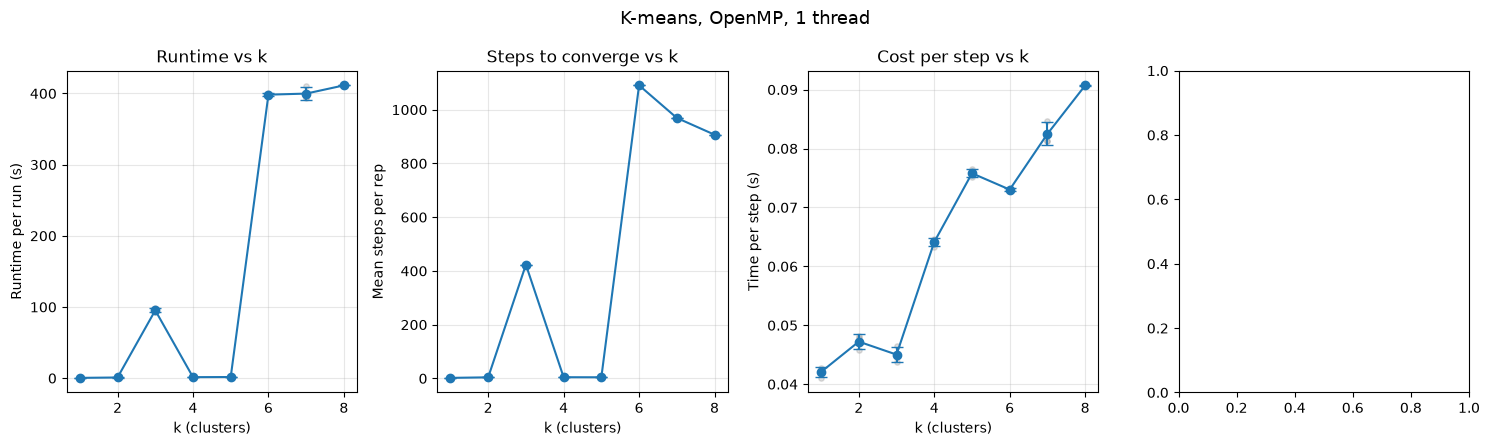

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def parse_steps(s):
    return np.array([int(v) for v in str(s).split(";") if v.strip()])

df = load_results("omp_1thread.csv")
df = df[df["threads"] == 1].copy()

steps = df["steps"].apply(parse_steps)
df["steps_total"] = steps.apply(np.sum)
df["steps_mean"]  = steps.apply(np.mean)
df["perstep"]     = df["seconds"] / df["steps_total"]

summary = (
    df.groupby("k")
    .agg(
        seconds_mean=("seconds", "mean"),   seconds_std=("seconds", "std"),
        steps_mean_mean=("steps_mean", "mean"), steps_mean_std=("steps_mean", "std"),
        steps_total_mean=("steps_total", "mean"), steps_total_std=("steps_total", "std"),
        perstep_mean=("perstep", "mean"),   perstep_std=("perstep", "std"),
        bestdist=("bestdist", "min"),
        n_runs=("run", "count"),
    )
    .reset_index()
    .fillna(0)
)
print(summary.to_string(index=False))

# ---- Plot ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# (raw column, mean column in summary, std column in summary, ylabel, title)
panels = [
    ("seconds",    "seconds_mean",     "seconds_std",     "Runtime per run (s)",    "Runtime vs k"),
    ("steps_mean", "steps_mean_mean",  "steps_mean_std",  "Mean steps per rep", "Steps to converge vs k"),
    ("perstep",    "perstep_mean",     "perstep_std",     "Time per step (s)",      "Cost per step vs k"),
]
for ax, (raw, m, s, ylabel, title) in zip(axes, panels):
    ax.errorbar(summary["k"], summary[m], yerr=summary[s], marker="o", capsize=4)
    ax.scatter(df["k"], df[raw], alpha=0.25, s=15, color="gray")
    ax.set_xlabel("k (clusters)"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(alpha=0.3)

fig.suptitle("K-means, OpenMP, 1 thread", fontsize=13)
fig.tight_layout()
#fig.savefig("kmeans_1thread_k.png", dpi=150)
plt.show()

For k=6
 threads       mean      std  n_runs
       1 397.488000 1.323047       3
      16  27.066633 0.887008       6
      64   8.022925 0.787966       6
     128   8.150635 0.322052       6
     192  13.396750 0.340458       6


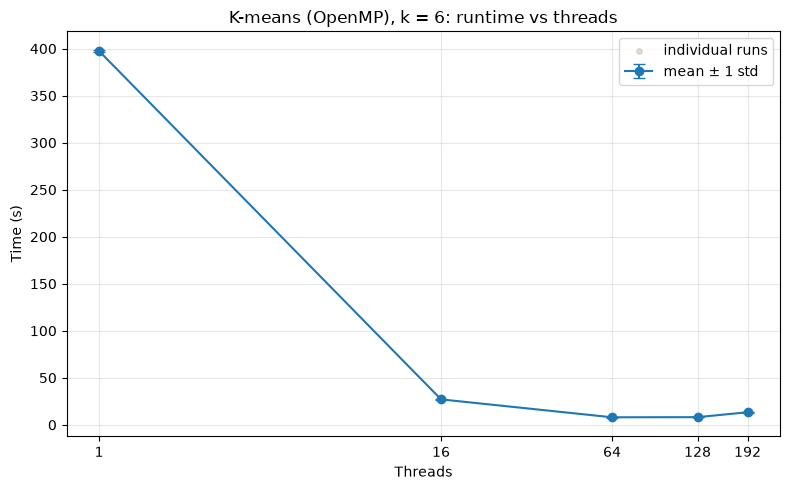

In [57]:
df = load_results("omp_thread_k.csv")
d6 = df[df["k"] == 6]
#print(d6)

summary = (
    d6.groupby("threads")["seconds"]
    .agg(mean="mean", std="std", n_runs="count")
    .reset_index()
    .fillna({"std": 0})
    .sort_values("threads")
)
print("For k=6")
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(summary["threads"], summary["mean"], yerr=summary["std"],
            marker="o", capsize=4, linewidth=1.5, label="mean ± 1 std")
ax.scatter(d6["threads"], d6["seconds"], alpha=0.25, s=15, color="gray", label="individual runs")

ax.set_xscale("log", base=2)
ax.set_xticks(summary["threads"])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("Threads")
ax.set_ylabel("Time (s)")
ax.set_title("K-means (OpenMP), k = 6: runtime vs threads")
ax.grid(alpha=0.3, which="both")
ax.legend()

fig.tight_layout()
#fig.savefig("kmeans_k6_threads.png", dpi=150)
plt.show()

### Varierende threads & k
We hebben vanalle cluster counts laten runnen voor vanalle thread counts. Hier is een korte plot van de speedups vergeleken met de k=1 run. Zie hier boven


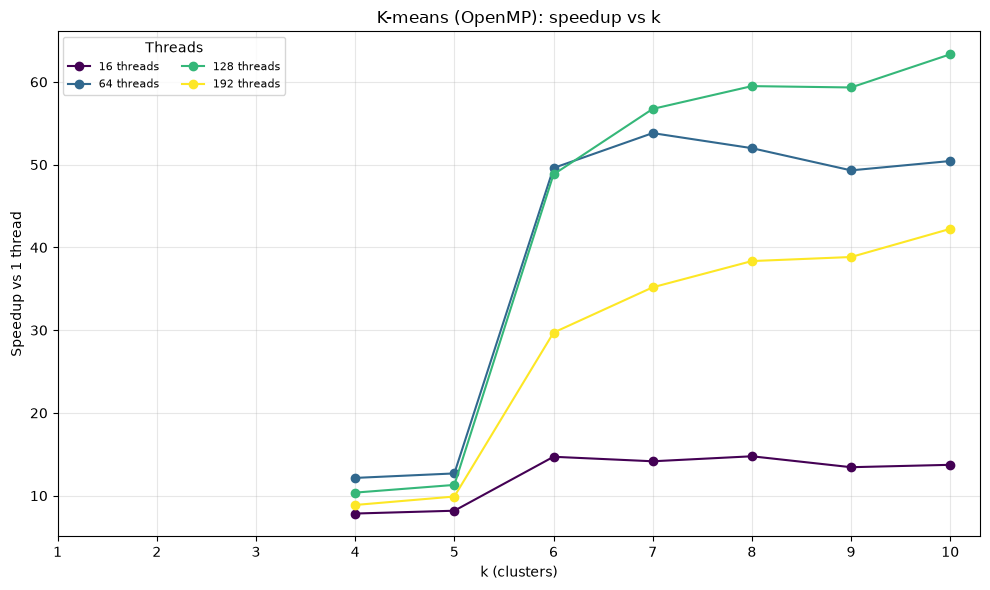

In [59]:
df = pd.concat(
    [load_results("omp_1thread.csv"), load_results("omp_thread_k.csv")],
    ignore_index=True,
)

mean_time = df.pivot_table(index="k", columns="threads", values="seconds", aggfunc="mean")
# T(1) / T(n), per k
speedup = mean_time.rdiv(mean_time[1], axis=0)

fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap("viridis")
threads = [t for t in speedup.columns if t != 1]

for i, t in enumerate(threads):
    ax.plot(speedup.index, speedup[t], marker="o", linewidth=1.5,
            color=cmap(i / max(len(threads) - 1, 1)), label=f"{t} threads")

ax.set_xlabel("k (clusters)")
ax.set_ylabel("Speedup vs 1 thread")
ax.set_title("K-means (OpenMP): speedup vs k")
ax.set_xticks(speedup.index)
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=8, title="Threads")

fig.tight_layout()
#fig.savefig("kmeans_speedup_vs_k.png", dpi=150)
plt.show()

In [ ]:
# Speedup for all 
df_one = load_results("omp_1thread.csv")
df_multi = load_results("omp_thread_k.csv")

df = pd.concat([df_one, df_multi], ignore_index=True)
mean_time = df.pivot_table(index="k", columns="threads", values="seconds", aggfunc="mean")

# Speedup = ser / par, per k
speedup = mean_time.rdiv(mean_time[1], axis=0)

print(speedup)

threads  1          16         64         128        192
k                                                       
1        1.0        NaN        NaN        NaN        NaN
2        1.0        NaN        NaN        NaN        NaN
3        1.0        NaN        NaN        NaN        NaN
4        1.0   7.841369  12.146368  10.370948   8.875260
5        1.0   8.180981  12.688192  11.298829   9.897466
6        1.0  14.700849  49.595690  48.818589  29.701420
7        1.0  14.156171  53.813183  56.736672  35.177736
8        1.0  14.759806  51.993407  59.490984  38.350137
9        1.0  13.440242  49.310138  59.329173  38.839955
10       1.0  13.728497  50.440579  63.336641  42.240938


# OUDE STUFF
da moete we nimeer bespreken


# Vragen

1. *Schets je werkwijze, maw leg uit wat je geparallelliseerd hebt en waarom. Zijn er delen die je bewust niet geparallelliseerd hebt (en waarom niet)? Hoe past dit bij de keuze van je dataset en parameters (k, repetitions)?*

Zoals eerder vermeld, we paralleliseerden op de twee kern loops, over de repetitions en over de point-comparisons. De logica erachter is eenvoudig.
De eerste berekend verschillende iteraties van het algorithme tegelijk, om te voorkomen dat N stappen van het algorithme K keren serieel berekend worden, en laat elke iteratie tegelijk gebeuren.
De andere loop versnelt het algorithme zelf, door N punten te verdelen in een aantal 'groups' die parallel berekend worden. Een OpenMP Reduction, dus.

In-code hebben we de optie voorzien om beide aan of uit te zetten, en zo met nested loops te werken indien bijde gebruikt worden.

Something we explicitedly decided not to parallelize is the `while(changed){}` loop. Het lijkt op eerste zicht een goed idee: run verschillende iteraties tegelijk, maar dat gaat niet echt. Elke iteratie hangt af van het vorige door de ge-update cluster positie. Als men dit in parallel zou runnen moet elke iteratie de vorige awaiten, en runnen we feitlijk een serieel programma met meer overhead. 

De optie om kolom-gewijs te parallelizeren was er ook, om bvb de kolommen van de dataset te verdelen over threads. Dit zou bvb betere presetatie geven bij datasets zoals `drivFaceD`, die 606 rows maar 6400 kolommen heeft. We hebben bewust beslist dit niet te doen, of te houden als test achteraf. Hierdoor zijn we gebleven met datasets met weinig dimensies maar veel rows, zoals `100000x5`.


2. *Maak een vergelijking van je seriële uitvoertijd met die van je OpenMP implementatie voor 1 thread. Baseer dit op een aantal herhaalde metingen*

Gemiddelde uitvoertijden op 1 thread (dataset `100000x5`):

| versie | tijd (s) |
|---|---|
| `serial` | 4.51 |
| `serial-naive` | 4.52 |
| `omp-naive` (1 thread) | 3.57 |
| `omp` (1 thread) | 8.07 |

De geoptimaliseerde `omp` versie is op 1 thread bijna dubbel zo traag als de seriële versie. Dat is de prijs van de aanpak: per iteratie van de `while(changed)` loop wordt een parallelle regio opgestart, krijgt elke thread een eigen `localCentroidMap` die telkens opnieuw gealloceerd en daarna samengevoegd wordt in een `critical` sectie, en komen er reducties en de `guided` scheduler bij. Met 1 thread levert dat niets op, maar het werk wordt wel gedaan. Dit extra werk is dus vaste overhead die pas terugverdiend wordt bij meerdere threads (zie vraag 3). `omp-naive` heeft die structuur niet, en met 1 thread is er ook geen conflict op de `critical` secties, vandaar de lage tijd. Dat die zelfs sneller is dan `serial` (-20.8 %) is onverwacht; we hebben dit niet verder onderzocht (mogelijk verschillen in de code of in de compileroptimalisaties), dus we trekken hier geen sterke conclusie uit.

![](./img/openmp1thread.png)

3. *Toon (figuren!) hoe de efficiëntie en speedup veranderen met het gebruikte aantal threads/cores. Denk er weer aan dat je je metingen herhaalt zodat je bvb gemiddelde en standaardafwijking kan tonen, en vermeld dit aantal. Gebruik de gemiddelde uitvoertijd van de 1-thread OpenMP versie als referentietijd. Bespreek de schaalbaarheid van je implementatie.*

Zoals verduidelijkt in het figuur, de speedup van `omp` is vrij goed, en volgt de maximale speedup nauw. Deze versie werkt met reducties om te voorkomen dat er gewachten moet worden op shared resources. Verder helpt de guided scheduler met de workload verdelen over alle threads.
Dit ligt tegenstrijdig met de naive implementatie, waar veel gebruik wordt gemaakt van critical secties. Het is logisch dat de speedup heel fel afneemt, want de rekentijd verhoogt ook veel: met meer threads zijn er critical secties die tegelijk één zelfde shared buffer willen accessen, en dus toenemenede conflicten.

Gemiddelde uitvoertijd, speedup en efficiëntie (referentie: `omp` op 1 thread = 8.07 s):

| threads | `omp` tijd (s) | speedup | efficiëntie | `omp-naive` tijd (s) | speedup |
|---|---|---|---|---|---|
| 1 | 8.07 | 1.00 | 100 % | 3.56 | 1.00 |
| 2 | 4.19 | 1.92 | 96.2 % | 16.70 | 0.21 |
| 4 | 2.25 | 3.58 | 89.5 % | 30.20 | 0.12 |
| 8 | 1.33 | 6.06 | 75.7 % | 42.25 | 0.084 |
| 16 | 0.99 | 8.11 | 50.7 % | 53.79 | 0.066 |

`omp` en `omp-2` gebruiken onderliggen identiek dezelde functie, te merken aan hoe de gemiddelden extreem dicht bij elkaar liggen (op 1 thread 8.069 s vs 8.070 s, op 16 threads 0.994 s vs 0.991 s, dus verschillen van maximaal ongeveer 0.3 %). Elke configuratie is 3 keer gemeten; hieronder gebruiken we de steekproef-standaardafwijking over die 3 runs (de foutbalken in de figuren zijn ±1 std).
Voor `omp` is de spreiding zeer klein: tot 8 threads minder dan 0.25 % van het gemiddelde (bv. 1.332 ± 0.003 s op 8 threads) en op 16 threads 0.99 ± 0.02 s (±1.7 %), wat een speedup van 8.11 ± 0.14 geeft.  De getoonde trends (efficiëntie die zakt van 96 % naar 51 %) zijn dus duidelijk groter dan de meetruis.
Bij `omp-naive` is de spreiding veel groter (bv. 30.2 ± 3.2 s op 4 threads en 53.8 ± 8.9 s op 16 threads, tot ~16 % van het gemiddelde), wat past bij conflicten om de `critical` secties die van run tot run sterk verschillen. Met slechts 3 runs per configuratie blijven deze standaardafwijkingen zelf wel een grove schatting.

`omp` schaalt goed tot 4 threads (efficiëntie ~90 %) en nog redelijk tot 8 threads (~76 %), maar op 16 threads zakt de efficiëntie naar ~51 %. De speedup blijft stijgen (8.1 op 16 threads), maar duidelijk onder het ideaal (16). Dit is verwacht: de `critical` merge van de `localCentroidMap` en de barrières per iteratie vormen seriële/synchronisatiekost die niet kleiner wordt met meer threads, terwijl het parallelle werk per thread wel kleiner wordt. Dit is ook te zien in de tweede figuur (efficiëntie). Voor `omp-naive` is er helemaal geen schaling: de tijd stijgt van 3.6 s (1 thread) tot 53.8 s (16 threads), omdat alle threads wachten op dezelfde `critical` secties. En hoe meer threads, hoe groter de wachtrij.

Deze grafiek bespreken metingen van 1, 2, 4, 8 en 16 threads. Men ziet duidelijk hoe de `naive` drastisch daalt, terwijl de 'normale' versie versnelt, en het stagneren 

![Speedup](./img/speedup.png)



4. *Deze metingen kan je gebruiken (zoals in de theorie) om de seriële fractie te schatten voor een bepaald aantal threads. Gebruik de metingen voor 8 threads, en schat zo de seriële fractie (de gemiddelde tijden gebruiken volstaat, bvb standaardafwijking hoeft niet).*

De wet van Amdahl voorspelt de theoretische maximale speedup $S(p)$ van een programma op basis van de parallelle fractie $P \in [0, 1]$, die we herleiden om P te isoleren:

$$
S = \frac{1}{((1 - P) + P / p)} \\
=>  (1 - P) + \frac{P}{p} = \frac{1}{S} \\
=> P * (1/p - 1) = \frac{1}{S} - 1 \\
=> P = \frac{1 - \frac{1}{S}}{1 - \frac{1}{p}}
$$

Zo berekenen we dat $P = 0.954$, dus een serieel fractie van ogv 4.5%.



5. *Op basis van deze seriële fractie kan je dan weer de uitvoertijd schatten voor 16 threads. Doe dit, vergelijk met je gemeten uitvoertijd voor 16 threads, en bespreek het verschil.*

Uit de metingen voor 8 threads volgt $P = \frac{1 - 1/6.06}{1 - 1/8} \approx 0.954$, dus een seriële fractie van 4.6%. Daarmee wordt de verwachte uitvoertijd bij $p = 16$:

$$
T(16) = T(1) \cdot \left((1 - P) + \frac{P}{16}\right) = 8.069 \cdot (0.0458 + 0.0596) \approx 0.85 \text{ s}
$$

dit komt overeen met een verwachte speedup van 9.5.

Gemeten op 16 threads: 0.99 s (speedup 8.11). De voorspelling is dus optimistisch: de werkelijke tijd ligt ongeveer 17 % hoger. De wet van Amdahl houdt enkel rekening met een vaste seriële fractie, maar in werkelijkheid groeit de overhead met het aantal threads: meer threads wachten op de `critical` merge van de `localCentroidMap`, er zijn meer lokale kopieën om te alloceren en samen te voegen, meer barrières en een slechtere load balancing bij weinig werk per thread, en er is mogelijk concurrentie voor geheugenbandbreedte.
Door $P$ te berekenen uit de gemeten tijd voor 16 threads bekomen we $P = 93.5%$, en $S = 6.5$ grosso modo. Dit betekend dat ofwel het stuk seriele code groter wordt, ofwel de overhead van synchronisatie groeit. Aangezien de broncode niet verandert, voila. Een oplossing die beter synchronisatie & awaits voorkomt zou dus beter presteren en een hogere efficientie hebben.


6. *Gebruik je metingen/berekeningen om je verwachtingen te beschrijven als je meer en meer cores ter beschikking krijgt. Wat als dit oneindig veel zou zijn? Wat wordt de uitvoertijd in dat geval?*

Volgens Amdahl is de uitvoertijd met oneindig veel cores enkel nog de seriële fractie: $T(\infty) = (1 - P) \cdot T(1) \approx 0.0458 \cdot 8.07 \approx 0.37$ s, dus een maximale speedup van $1/(1-P) \approx 21.8$. Met meer cores gaat de speedup dus steeds trager stijgen en vlakt die af (de efficiëntie daalt al van 96 % op 2 threads naar 51 % op 16 threads). Aangezien we niet veel data hebben om ons op te baseren,
Dit is nog een optimistische bovengrens: omdat de overhead in onze implementatie met het aantal threads toeneemt, zie vorige vraag, halen we in de praktijk minder. Met de 16-thread schatting ($P = 93.5\%$) zou de grens zelfs maar $\approx 15.4$ zijn. Realistisch verwachten we dus dat meer dan ~16 threads op deze dataset weinig tot niets meer oplevert, en dat het zelfs trager kan worden.


7. *Welke manieren kan je bedenken om de schaalbaarheid nog te verbeteren (nog steeds met enkel OpenMP)? Hoeveel werk zouden ze vergen?*

De eerder besproken 'kolom' parallelisatie zou ingeschakeld kunnen worden. We schatten dat dit niet *enorm* complex is, maar wel veel kleine problemen zal veroorzaken, waardoor het wel tijd zou nemen om alles correct en efficiënt te krijgen. Het helpt vooral bij datasets met veel kolommen en weinig rijen, niet bij `100000x5`.

Het belangrijkste lijkt ons de overhead van vorige vragen te verminderen. We dachten eens een flamegraph te maken van het programma en bestuderen waar er het beeste processing verloren zou lopen, bvb heap allocations die onnodig in elke iteratie van de lus gebeuren.
Met enkel OpenMP zou het misschien mogelijk zijn om te reduceren ipv critical secties te gebruiken. De manier waarvan zijn we niet zeker, en eerlijk hebben we even de tijd niet meer om uit te proberen voor indienen. Het kan ook zijn dat een andere scheduler met gespecificeerde chunk size voordelig kan zijn. Meer tests nodig.



# Redeneren (notities en bijkomende gedachten)

## Wat kunnen we allemaal parallelliseren?

Er zijn hier twee voornaamste opties:

1. De hoofdloop van de repetitions
2. De inner loop waar het algoritme effectief alle punten doorloopt

### Wat te veranderen

#### Implementatie Main
- Als we de main parallelliseren dan moeten we op voorhand de centroids initialiseren aangezien dit met raceconditions over de verschillende threads een probleem zou geven (heb ik ook zo ondervonden).
- Writing in files kan best pas achteraf gebeuren

**Uitvoering:**
We maken voor de meest gebruikte vectors een extra dimentie zodat we voor elke repetition een andere vector gebruiken. Dit zorgt ervoor dat er geen raceconditions op dat vlak voorkomen.
```cpp
std::vector<std::vector<double>> centroids(repetitions, std::vector<double>(numClusters * size.cols));
std::vector<std::vector<int>> pointsCentroid(repetitions, std::vector<int>(size.rows));
```

We initialiseren de centroids dan op voorhand zodat ze altijd correct en gelijk worden geïnitialiseerd (zie problemen).

In plaats van naar de debug files te schrijven, maken we een vector aan voor deze en schrijven daarnaar. Na de loop kunnen we dan dit nog gaan wegschrijven.

```cpp
std::vector<std::vector<std::vector<double>>> centroidsDebug(repetitions);
std::vector<std::vector<std::vector<int>>> clustersDebug(repetitions);
```
>De meerdere dimenties was achteraf gezien totaal onnodig aangezien we toch maar enkel de eerste iteratie moeten wegsschrijven.

#### Implementatie Inner loop
- Oppassen voor schrijven naar de pointsmap => moet critical voor gebruiken of een betere oplossing voor bedenken.
- Lezen van zaken is geen probleem maar schrijven wel

##### Implementatie 1: Extra Naïef
Bij deze implementatie zijn we simpelweg `#pragma omp parallel for schedule(guided)` gaan toepassen en dan overal waar een gedeelde variabele overschreven zou worden zetten we of `critical` of `atomic`. 
Deze aanpak werkte, maar was vrij traag. We haalden hieruit dat het grootste gedeelte van de tijd threads aan het wachten waren op toegang tot een variabele om te schrijven. Als dit niet vaak moet gebeuren dan is dit geen probleem, maar in deze code deden we dit voor elk punt. Als we dan bijvoorbeeld 100.000 punten in een bestand hebben dan zullen we 100.000 keer een kans op conflicten hebben, wat natuurlijk niet ideaal is. Dit hebben we dan aangepakt in een aantal verbeteringen in versie 2.

##### Implementatie 2: Al iets minder naïef
Zoals in vorige implementatie reeds gezegd ging een groot deel verloren door het wachten tot andere threads klaar waren met het schrijven naar gedeelde variabelen.
Deze variabelen zijn onder andere:
- `changed`: Duid aan wanneer een punt tot een andere cluster behoort dan vorige iteratie
- `avgDist`: Telt de gemiddelde afstand op zodat een beste cluster berekend kan worden
- `centroidMap`: Deze variabele was veruit de belangrijkste die we hier konden optimaliseren. Elke iteratie moesten punten worden opgeteld en naar deze map worden geschrijven van over elke iteratie. Dit zorgde voor de meeste overhead. We behandelde deze hiervoor met `critical` maar dat was dus een probleem.

OPLOSSING:
De kleine variabelen zoals "changed" en  "avgDist" konden we makkelijk al in een reduce expressie van de for loop zelf steken. 
```cpp
#pragma omp parallel reduction(+ : avgDist) reduction(|| : changed)
```

Daarnaast kunnen we in dit stukje code al een belangrijke veranderingzien voor de volgende aanpassing.
In plaats van elke iteratie naar een *gedeelde* `centroidMap` te laten schrijven zoals hieronder:
```cpp
for (int c = 0; c < size.cols; c++)
			{
				// std::cout << allData[c+i] << " , ";
				centroidMap[cIndex][c] += allData[ii * size.cols + c];
			}
			centroidMap[cIndex][size.cols] += 1;
```

Gaan we dit een beetje anders aanpakken. We behouden de logica van de centroidMap maar vervangen deze door een vanboven gedefiniëerde `localCentroidMap`.
Aangezien we deze moeten definiëren op de plek waar een thread begint kunnen we ook niet meer *beginnen* met een `omp parallel for`.
In plaats daarvan beginnen we met het opstarten van een `omp parallel` wat ervoor zorgt dat meerdere threads deze loop al proberen uit te voeren. Hierachter definiëren we dan de nieuwe localCentroidMap:
```cpp
#pragma omp parallel reduction(+ : avgDist) reduction(|| : changed)
	{
		std::vector<std::vector<double>> localCentroidMap(
		    centroids.size() / size.cols, std::vector<double>(size.cols + 1)); 
``` 

Als we nu echter aan de loop zouden beginnen zou gewoon verschillende keren exact dezelfde loop afgaan. We moeten daarom nog steeds `omp for` definiëren, wat we daarna ook doen.
```cpp
#pragma omp for nowait
		for (size_t ii = 0; ii < size.rows; ++ii)
		{
``` 
Alle andere logica blijft exact hetzelfde. De kleine variabelen worden bij compileren omgezet naar een priv_var van OMP wat ervoor zorgt dat deze elke loop onafhankelijk berekende kunnen worden en later gewoon volgende de correct operatie worden bijeengevoegd.

De localCentroidMaps moeten na deze loop nog enkel overlopen worden en samengevoegd worden in de shared `centroidMap`:
```cpp
#pragma omp critical
		{
			for (int r = 0; r < centroidNumber; r++)
			{
				for (int c = 0; c < size.cols + 1; c++)
				{
					centroidMap[r][c] += localCentroidMap[r][c];
				}
			}
		}
```
> Note: Ik had hier een klein probleem opgelopen omdat ik was vergeten niet size.cols + 1 te doen. De laatste index staat voor het aantal punten verbonden aan de centroid waardoor het altijd op "0" bleef. Hierdoor gingen we maar 2 iteraties door aangezien er volgens het algoritme niets meer verandert was nadien.


### Problemen voor Main

We moeten ook oppassen voor dataraces in de main functie en er zijn een paar mogelijke plekken waar deze kunnen voorkomen.

1. We kunnen in principe over critical gaan gebruiken voor centroids enzovoorts maar dat gaat ervoor zorgen dat we vrij vaak moeten wachten tot andere threads klaar zijn dus in plaats daarvan maken we voor elke repetition een vector aan waarin we de waarden voor die rep in kunnen opslaan. Dit kunnen we later ook gaan gebruiken voor het schrijven naar de centroid files en de trace files
2. Na eerst gewoon in de loops de centroidInit te proberen toepassen, stootten we tegen het probleem aan dat elke keer we een nieuw programma opstarten, de random centroids anders geïnitialiseerd werden. Dit komt waarschijnlijk door race conditions tussen the verschillende threads.
    - OPLOSSING: We zetten even een aparte loop uit de parallelle loop om de juiste centroids te bekomen zodat we effectief kunnen meten.
3. Schrijven naar de files moet ook op een enkele thread gebeuren dus we zouden hier de "master" thread kunnen gebruiken maar dat is niet heel efficiënt dus in plaats daarvan  vervangen we op de plekken waar we schrijven naar een file, de file door een vector waaruit we de data later kunnen halen en uit de loop kunnen schrijven naar de correcte file.

### Problemen voor Innerloop
Hier zijn we tegen een hoop meer problemen aan gestoten.
De standaard parallellisatie was makkelijk te verwerken hierin. 
Op een aantal plekken waar nodig zetten we simpelweg `#pragma omp critical/atomic` en dat loste het probleem op.
Vanboven aan de loop zetten we `#pragma omp parallel for schedule(guided)` aangezien uit een van de vorige oefeningen dit het simpelste leek om optimaal te implementeren.

#### Probleem 1: Nesting staat standaard uit in OMP
Aangezien we eerst probeerde dubbele parallellisatie toe te passen vanop beide loops leek alles perfect te werken. Maar dit was echter onder de code niet het geval. OMP zet standaard de variabele `OMP_NESTED` op false. Wat betekend dat we niet meerdere lagen in elkaar kunnen parallel werken. Dit zorgde ervoor dat het aan de oppervlakte leek dat alles werkte, maar er werd maar 1 thread gebruikt voor de tweede loop uit te voeren, wat dit niet beter maakte dan seriële uitvoeren van die functie. 
OPLOSSING: Door bij het aanroepen van het programma de variabele op true te zetten `OMP_NESTED=true ./kmeans ...` werd er verder dan één niveau gekeken. Later hebben we echter beslist dat dit niet de ideale manier is om een programma te parallelliseren en dat er wel effectief een reden is waarom dit standaard af staat.

#### Probleem 2: Critical neemt teveel tijd in
Reeds uitgelegd in implementatie 2 van innerloop.

## Te Testen en te meten

- Seriël vs OMP implementaties
- Speedup berekenen
- Test voor verschillende hoeveelheden threads
- Test nested vs Only outer para vs Only inner para
- Test Inner para latest vs Inner para first
- Bereken theoretische speedup en vergelijk met praktisch verkregen speedup.
- Bereken ook de efficiëntie van het algoritme
- Seriële imp vs OMP implementatie op 1 thread

- Visualiseer deze metingen ook. Dat kan gemakkelijk voor de vergelijkingen met 1 script.